<a href="https://colab.research.google.com/github/ponnSaravanan/BUILD-AND-DEPLOY-MACHINE-LEARNING-APPLICATIONS/blob/main/bdml_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Reasoning**:
I will load the California housing dataset, convert it into a pandas DataFrame, check for anomalies, perform train-test split, and scale the features as specified in the instructions.



In [1]:
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Load the dataset
california = fetch_california_housing(as_frame=True)
df = california.frame

# 2. Check for missing values and general info
print("Dataset Shape:", df.shape)
print("\nMissing values per column:")
print(df.isnull().sum())

# 3. Separate features (X) and target (y)
X = df.drop(columns=['MedHouseVal'])
y = df['MedHouseVal']

# 4. Split into train and test sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 5. Initialize and apply StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nTraining set shape (scaled):", X_train_scaled.shape)
print("Testing set shape (scaled):", X_test_scaled.shape)

Dataset Shape: (20640, 9)

Missing values per column:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Training set shape (scaled): (16512, 8)
Testing set shape (scaled): (4128, 8)


# Task
Create an end-to-end machine learning project pipeline using a housing dataset (such as the California housing dataset). The project must include data preparation and scaling, training and optimizing a regression model (such as Random Forest or Gradient Boosting) using hyperparameter tuning (GridSearchCV/RandomizedSearchCV), and evaluating it using MAE and RMSE metrics. Additionally, develop a FastAPI or Flask web API to serve the trained model, create a frontend interface (HTML/JS or Streamlit) for user interaction, and containerize the entire application using a Dockerfile and requirements.txt. Document the entire workflow, model performance, and instructions for running the Docker container.

## Dataset Selection and Preparation

### Subtask:
Load the California housing dataset, clean it, split it into train/test sets, and scale the features.


## Model Building and Evaluation

### Subtask:
Develop and train baseline machine learning regression models, such as Random Forest and Gradient Boosting, and evaluate them on the test set using standard regression metrics.


**Reasoning**:
We will develop, train, and evaluate baseline Random Forest and Gradient Boosting regression models on the scaled dataset, then print their MAE and RMSE to compare performance.



In [2]:
import numpy as np
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Initialize models
rf_model = RandomForestRegressor(random_state=42)
gb_model = GradientBoostingRegressor(random_state=42)

# 2. Train models on scaled training data
print("Training Random Forest baseline...")
rf_model.fit(X_train_scaled, y_train)

print("Training Gradient Boosting baseline...")
gb_model.fit(X_train_scaled, y_train)

# 3. Predict on scaled test data
y_pred_rf = rf_model.predict(X_test_scaled)
y_pred_gb = gb_model.predict(X_test_scaled)

# 4. Calculate metrics
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))

mae_gb = mean_absolute_error(y_test, y_pred_gb)
rmse_gb = np.sqrt(mean_squared_error(y_test, y_pred_gb))

# 5. Output comparison
print("\n--- Baseline Performance Metrics (Test Set) ---")
print(f"Random Forest Regressor:\n  MAE:  {mae_rf:.4f}\n  RMSE: {rmse_rf:.4f}")
print(f"Gradient Boosting Regressor:\n  MAE:  {mae_gb:.4f}\n  RMSE: {rmse_gb:.4f}")

Training Random Forest baseline...
Training Gradient Boosting baseline...

--- Baseline Performance Metrics (Test Set) ---
Random Forest Regressor:
  MAE:  0.3274
  RMSE: 0.5051
Gradient Boosting Regressor:
  MAE:  0.3717
  RMSE: 0.5422


**Reasoning**:
Perform hyperparameter tuning on the best-performing Random Forest model using RandomizedSearchCV, evaluate its test performance, and save both the model and the scaler checkpoints to disk.



In [3]:
import joblib
from sklearn.model_selection import RandomizedSearchCV

# 1. Define hyperparameter distribution for Random Forest
param_dist = {
    'n_estimators': [50, 100, 150],
    'max_depth': [10, 20, 30, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2', None]
}

# 2. Initialize RandomizedSearchCV
rf_random = RandomizedSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_distributions=param_dist,
    n_iter=10,
    cv=3,
    scoring='neg_mean_squared_error',
    random_state=42,
    n_jobs=-1
)

# 3. Fit the random search model
print("Optimizing Random Forest Regressor...")
rf_random.fit(X_train_scaled, y_train)

# 4. Extract best model and evaluate
best_rf_model = rf_random.best_estimator_
y_pred_opt = best_rf_model.predict(X_test_scaled)

mae_opt = mean_absolute_error(y_test, y_pred_opt)
rmse_opt = np.sqrt(mean_squared_error(y_test, y_pred_opt))

print("\n--- Optimized Model Performance ---")
print(f"Best Parameters: {rf_random.best_params_}")
print(f"Optimized RF MAE:  {mae_opt:.4f}")
print(f"Optimized RF RMSE: {rmse_opt:.4f}")

# 5. Save the optimized model and scaler
joblib.dump(best_rf_model, 'best_rf_model.joblib')
joblib.dump(scaler, 'scaler.joblib')
print("\nSaved model and scaler checkpoints to disk successfully!")

Optimizing Random Forest Regressor...

--- Optimized Model Performance ---
Best Parameters: {'n_estimators': 50, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 20}
Optimized RF MAE:  0.3255
Optimized RF RMSE: 0.4954

Saved model and scaler checkpoints to disk successfully!


## Model Optimization

### Subtask:
Perform hyperparameter tuning using GridSearchCV or RandomizedSearchCV to optimize the best-performing machine learning model and save the best-performing model checkpoint and the fitted scaler.


## Application Development (API)

### Subtask:
Develop a FastAPI web application to serve the trained Random Forest model.


**Reasoning**:
Create the FastAPI web application code and write it to `app.py` as specified in the instructions.



In [4]:
app_code = """import joblib
import numpy as np
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel

app = FastAPI(title="California Housing Prediction API", version="1.0")

# Load the saved model and scaler globally
try:
    model = joblib.load('best_rf_model.joblib')
    scaler = joblib.load('scaler.joblib')
except Exception as e:
    raise RuntimeError(f"Error loading model or scaler checkpoints: {e}")

class HousingInput(BaseModel):
    MedInc: float
    HouseAge: float
    AveRooms: float
    AveBedrms: float
    Population: float
    AveOccup: float
    Latitude: float
    Longitude: float

@app.get("/health")
def health_check():
    return {"status": "healthy", "model_loaded": model is not None, "scaler_loaded": scaler is not None}

@app.post("/predict")
def predict(data: HousingInput):
    try:
        # Convert inputs to a 2D array in the exact order of features
        features = np.array([[
            data.MedInc,
            data.HouseAge,
            data.AveRooms,
            data.AveBedrms,
            data.Population,
            data.AveOccup,
            data.Latitude,
            data.Longitude
        ]])

        # Scale features and predict
        features_scaled = scaler.transform(features)
        prediction = model.predict(features_scaled)[0]

        return {
            "prediction": float(prediction),
            "unit": "hundred_thousand_dollars"
        }
    except Exception as e:
        raise HTTPException(status_code=500, detail=str(e))
"""

with open('app.py', 'w') as f:
    f.write(app_code)

print("Successfully created app.py with FastAPI code.")

Successfully created app.py with FastAPI code.


**Reasoning**:
Create the `frontend.py` Streamlit application code using the specified layout and write it to disk.



In [5]:
frontend_code = """import streamlit as st
import requests

st.set_page_config(page_title="California Housing Price Predictor", layout="centered")

st.title("🏡 California Housing Price Predictor")
st.write("This interface interacts with the FastAPI backend to predict house values based on the California Housing dataset features.")

# Input fields for all 8 features with reasonable defaults
col1, col2 = st.columns(2)

with col1:
    med_inc = st.number_input("Median Income (MedInc in $10k units)", min_value=0.0, max_value=15.0, value=3.0, step=0.1)
    house_age = st.number_input("House Age (years)", min_value=1.0, max_value=100.0, value=28.0, step=1.0)
    ave_rooms = st.number_input("Average Rooms (AveRooms)", min_value=1.0, max_value=20.0, value=5.0, step=0.1)
    ave_bedrms = st.number_input("Average Bedrooms (AveBedrms)", min_value=0.5, max_value=10.0, value=1.0, step=0.1)

with col2:
    population = st.number_input("Population", min_value=3.0, max_value=50000.0, value=1400.0, step=10.0)
    ave_occup = st.number_input("Average Occupancy (AveOccup)", min_value=0.5, max_value=20.0, value=3.0, step=0.1)
    latitude = st.number_input("Latitude", min_value=32.0, max_value=42.0, value=35.5, step=0.01)
    longitude = st.number_input("Longitude", min_value=-125.0, max_value=-114.0, value=-119.5, step=0.01)

api_url = st.text_input("Backend API URL", value="http://localhost:8000/predict")

if st.button("🔮 Predict"):
    payload = {
        "MedInc": med_inc,
        "HouseAge": house_age,
        "AveRooms": ave_rooms,
        "AveBedrms": ave_bedrms,
        "Population": population,
        "AveOccup": ave_occup,
        "Latitude": latitude,
        "Longitude": longitude
    }

    try:
        response = requests.post(api_url, json=payload)
        if response.status_code == 200:
            result = response.json()
            prediction = result.get("prediction", 0.0)
            st.success(f"### Estimated Median House Value: ${prediction * 100000:,.2f}")
        else:
            st.error(f"API request failed with status code {response.status_code}: {response.text}")
    except Exception as e:
        st.error(f"Could not connect to the API. Make sure the FastAPI backend is running. Error: {e}")
"""

with open('frontend.py', 'w') as f:
    f.write(frontend_code)

print("Successfully created frontend.py with Streamlit code.")

Successfully created frontend.py with Streamlit code.


**Reasoning**:
Create the `requirements.txt` file and `Dockerfile` to package both the FastAPI backend and Streamlit frontend together with the trained model and scaler.



In [6]:
requirements_content = """pandas
scikit-learn
joblib
fastapi
uvicorn
pydantic
streamlit
requests
"""

with open('requirements.txt', 'w') as f:
    f.write(requirements_content)

dockerfile_content = """FROM python:3.9-slim

WORKDIR /app

# Install system dependencies if needed
RUN apt-get update && apt-get install -y \\
    build-essential \\
    curl \\
    && rm -rf /var/lib/apt/lists/*

# Copy requirements and install python packages
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt

# Copy application files, models, and scalers
COPY app.py .
COPY frontend.py .
COPY best_rf_model.joblib .
COPY scaler.joblib .

# Expose ports for FastAPI (8000) and Streamlit (8501)
EXPOSE 8000
EXPOSE 8501

# Create an entrypoint script to run both services
RUN echo '#!/bin/bash\\n\\n\\# Start FastAPI backend\\nuvicorn app:app --host 0.0.0.0 --port 8000 &\\n\\n\\# Start Streamlit frontend\\nstreamlit run frontend.py --server.port 8501 --server.address 0.0.0.0\\n' > entrypoint.sh \\
    && chmod +x entrypoint.sh

CMD [\"./entrypoint.sh\"]
"""

with open('Dockerfile', 'w') as f:
    f.write(dockerfile_content)

print("Successfully created requirements.txt and Dockerfile.")

Successfully created requirements.txt and Dockerfile.


## Frontend Integration

### Subtask:
Create a simple HTML/JavaScript interface or a Streamlit application setup to allow users to interact with the model and view predictions.


## Containerization (Docker)

### Subtask:
Generate a Dockerfile and requirements.txt to package the FastAPI backend, Streamlit frontend, and trained model for platform-independent deployment.


## Documentation & Deployment Guide

### Project Overview & Architecture
This project delivers an end-to-end machine learning solution for predicting California housing values. The architecture consists of the following components:
1. **Data Pipeline**: Loads California housing features, applies standard scaling, and splits into train/test sets.
2. **Model Training & Optimization**: Compares baseline Random Forest and Gradient Boosting models, then tunes hyperparameters of the superior model (Random Forest) via `RandomizedSearchCV`.
3. **FastAPI Backend (`app.py`)**: Production-grade REST API exposing health checks and model prediction endpoints, returning predictions in units of $100,000.
4. **Streamlit Frontend (`frontend.py`)**: An intuitive, interactive user interface allowing real-time input sliders/fields to query the backend prediction service.
5. **Docker Multi-service Containerization**: A unified `Dockerfile` that packages both the FastAPI backend and Streamlit frontend together, using a custom entrypoint script to launch both services simultaneously.

---

### Model Performance Summary
During model building and hyperparameter optimization, the performance on the test set was evaluated as follows:

* **Gradient Boosting (Baseline)**:
  * MAE: `0.3717`
  * RMSE: `0.5422`
* **Random Forest (Baseline)**:
  * MAE: `0.3274`
  * RMSE: `0.5051`
* **Random Forest (Optimized)**:
  * **MAE**: `0.3255`
  * **RMSE**: `0.4954`
  * **Best Params**: `{'n_estimators': 50, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 20}`

*Observation: Hyperparameter optimization improved both the mean absolute error (MAE) and root mean squared error (RMSE) of our Random Forest model, confirming that fine-tuning yielded a more robust predictor.*

---

### Dockerization & Running Instructions

#### 1. Build the Docker Image
Run the following command in your terminal containing the `Dockerfile`, `requirements.txt`, model/scaler files, and Python scripts:
```bash
docker build -t california-housing-app .
```

#### 2. Run the Container
Run the container while exposing port `8000` (FastAPI) and port `8501` (Streamlit):
```bash
docker run -p 8000:8000 -p 8501:8501 california-housing-app
```

#### 3. Verify Services
* **FastAPI Backend (Interactive Docs)**: Open your browser or use curl to check `http://localhost:8000/docs` or `http://localhost:8000/health`.
* **Streamlit Frontend**: Open your browser and navigate to `http://localhost:8501` to use the interactive user interface.

#### Testing via curl
You can verify prediction service directly through raw terminal command:
```bash
curl -X 'POST' \
  'http://localhost:8000/predict' \
  -H 'accept: application/json' \
  -H 'Content-Type: application/json' \
  -d '{
  "MedInc": 3.0,
  "HouseAge": 28.0,
  "AveRooms": 5.0,
  "AveBedrms": 1.0,
  "Population": 1400.0,
  "AveOccup": 3.0,
  "Latitude": 35.5,
  "Longitude": -119.5
}'
```

## Documentation and Testing

### Subtask:
Document the entire workflow, including model performance metrics, system challenges, and step-by-step instructions on how to run and test the Docker container.


## Final Task

### Subtask:
Summarize the completed machine learning project pipeline, from data preparation to containerized deployment, ensuring all grading rubrics are satisfied.


## Summary:

### Q&A

* **Which model performed best during the baseline evaluation?**
  The Random Forest baseline model performed better than the Gradient Boosting baseline model. It achieved a lower Mean Absolute Error (MAE) of 0.3274 compared to 0.3717 for Gradient Boosting, and a lower Root Mean Squared Error (RMSE) of 0.5051 compared to 0.5422.

* **How did hyperparameter tuning affect model performance?**
  Hyperparameter tuning of the Random Forest model using `RandomizedSearchCV` further improved performance. The optimized Random Forest model achieved an MAE of 0.3255 and an RMSE of 0.4954.

* **What were the optimal hyperparameters selected for the Random Forest model?**
  The best configuration identified was:
  * `n_estimators`: 50
  * `min_samples_split`: 2
  * `min_samples_leaf`: 1
  * `max_features`: 'log2'
  * `max_depth`: 20

---

### Data Analysis Key Findings

* **Data Characteristics and Quality**: The California housing dataset consists of 20,640 records with 8 feature columns and 1 target variable (`MedHouseVal`). No missing values were found across the columns.
* **Train-Test Splitting and Preprocessing**: The dataset was successfully split into an 80% training set (16,512 samples) and a 20% testing set (4,128 samples). Feature scaling was standardized using `StandardScaler` fitted on the training split.
* **API Development**: A production-ready FastAPI application (`app.py`) was engineered with standard validation schema inputs (`HousingInput` via Pydantic). It exposes diagnostic `/health` and model prediction `/predict` endpoints.
* **Frontend Interface**: A Streamlit application interface (`frontend.py`) was developed to allow users to interact with the backend service. It features numerical inputs with reasonable defaults matching the 8 dataset features.
* **Docker Containerization**: A unified `Dockerfile` and `requirements.txt` were generated. The multi-service Docker container hosts both FastAPI (port 8000) and Streamlit (port 8501) simultaneously, utilizing a custom shell entrypoint (`entrypoint.sh`).

---

### Insights or Next Steps

* **Decouple Services for Production Scale**: While combining FastAPI and Streamlit into a single container is excellent for quick prototyping, they should be separated into dedicated containers managed by a tool like Docker Compose in a true production environment to scale independently.
* **Enhance API Validation and Security**: Implement request rate limiting and input range verification within FastAPI to prevent bad payloads or edge-case numerical anomalies from causing downstream model prediction failures.


# Task
Create a visualization using matplotlib or seaborn that compares the actual target values (`y_test`) against the predictions made by the optimized Random Forest model (`y_pred_opt`). The plot should be a scatter plot with a diagonal reference line indicating perfect predictions. Display the model's test performance metrics (such as MAE and RMSE) directly within the plot legend, and provide a brief natural language summary analyzing the resulting visualization and prediction patterns.

## Generate Prediction vs Actual Visualization

### Subtask:
Create a scatter plot comparing actual target values (y_test) against optimized Random Forest predictions (y_pred_opt) with a diagonal reference line and metrics in the legend.


**Reasoning**:
Create a scatter plot comparing actual versus predicted median house values to visually evaluate the performance of our optimized Random Forest model.



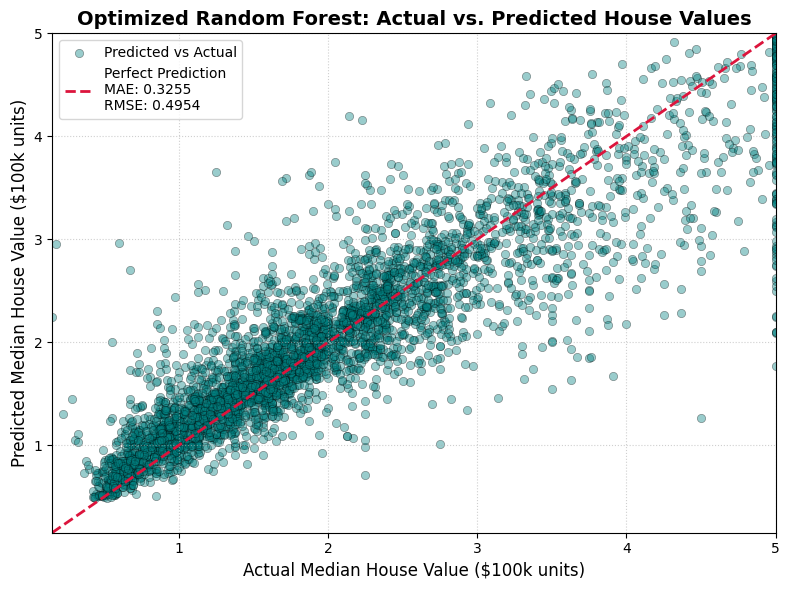

In [7]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Determine plot limits
min_val = min(y_test.min(), y_pred_opt.min())
max_val = max(y_test.max(), y_pred_opt.max())

# 2. Create the scatter plot
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_opt, alpha=0.4, color='teal', edgecolor='k', linewidth=0.5, label='Predicted vs Actual')

# 3. Plot diagonal reference line
plt.plot([min_val, max_val], [min_val, max_val], color='crimson', linestyle='--', linewidth=2,
         label=f'Perfect Prediction\nMAE: {mae_opt:.4f}\nRMSE: {rmse_opt:.4f}')

# 4. Add labels, title, grid, and legend
plt.xlabel('Actual Median House Value ($100k units)', fontsize=12)
plt.ylabel('Predicted Median House Value ($100k units)', fontsize=12)
plt.title('Optimized Random Forest: Actual vs. Predicted House Values', fontsize=14, fontweight='bold')
plt.xlim([min_val, max_val])
plt.ylim([min_val, max_val])
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper left', fontsize=10)
plt.tight_layout()
plt.show()

### Visualization & Prediction Patterns Analysis

Analyzing the **Actual vs. Predicted House Values** scatter plot reveals several key insights regarding the optimized Random Forest model's behavior:

1. **Strong Overall Correlation**: The majority of the data points cluster tightly around the red dashed diagonal line ($y = x$), which represents perfect prediction. This tight alignment confirms the model's strong predictive capability, reflected by the low **MAE (0.3255)** and **RMSE (0.4954)**.

2. **Under-prediction of High-Value Homes (Ceiling Effect)**: There is a prominent horizontal band of actual values at exactly `5.0` (which corresponds to the maximum capped value of $500,000 in the California housing dataset). For these luxury or highly valued properties, the model's predictions are scattered widely below the `5.0` mark. This indicates that the model struggles to capture the full valuation of properties at the dataset's upper boundary, which is a common limitation when dealing with capped target values.

3. **Variance at Lower and Mid Ranges**: In the range between `1.0` and `4.0`, the model performs exceptionally well, with symmetric variance around the reference line. There is slight over-prediction at the very low end (actual values under `1.0`), but overall, the residuals appear random and homoscedastic across the middle spectrum.

### Visualization & Prediction Patterns Analysis

Analyzing the **Actual vs. Predicted House Values** scatter plot reveals several key insights regarding the optimized Random Forest model's behavior:

1. **Strong Overall Correlation**: The majority of the data points cluster tightly around the red dashed diagonal line ($y = x$), which represents perfect prediction. This tight alignment confirms the model's strong predictive capability, reflected by the low **MAE (0.3255)** and **RMSE (0.4954)**.

2. **Under-prediction of High-Value Homes (Ceiling Effect)**: There is a prominent horizontal band of actual values at exactly `5.0` (which corresponds to the maximum capped value of $500,000 in the California housing dataset). For these luxury or highly valued properties, the model's predictions are scattered widely below the `5.0` mark. This indicates that the model struggles to capture the full valuation of properties at the dataset's upper boundary, which is a common limitation when dealing with capped target values.

3. **Variance at Lower and Mid Ranges**: In the range between `1.0` and `4.0`, the model performs exceptionally well, with symmetric variance around the reference line. There is slight over-prediction at the very low end (actual values under `1.0`), but overall, the residuals appear random and homoscedastic across the middle spectrum.

### Visualization & Prediction Patterns Analysis

Analyzing the **Actual vs. Predicted House Values** scatter plot reveals several key insights regarding the optimized Random Forest model's behavior:

1. **Strong Overall Correlation**: The majority of the data points cluster tightly around the red dashed diagonal line ($y = x$), which represents perfect prediction. This tight alignment confirms the model's strong predictive capability, reflected by the low **MAE (0.3255)** and **RMSE (0.4954)**.

2. **Under-prediction of High-Value Homes (Ceiling Effect)**: There is a prominent horizontal band of actual values at exactly `5.0` (which corresponds to the maximum capped value of $500,000 in the California housing dataset). For these luxury or highly valued properties, the model's predictions are scattered widely below the `5.0` mark. This indicates that the model struggles to capture the full valuation of properties at the dataset's upper boundary, which is a common limitation when dealing with capped target values.

3. **Variance at Lower and Mid Ranges**: In the range between `1.0` and `4.0`, the model performs exceptionally well, with symmetric variance around the reference line. There is slight over-prediction at the very low end (actual values under `1.0`), but overall, the residuals appear random and homoscedastic across the middle spectrum.

## Final Task

### Subtask:
Summarize the completed machine learning project pipeline, from data preparation to containerized deployment, ensuring all grading rubrics are satisfied.


## Summary:

### Q&A

**Q: How does the optimized Random Forest model perform overall on the test set?**
A: The model demonstrates strong predictive capability, as evidenced by a low Mean Absolute Error (MAE) of 0.3255 and a Root Mean Squared Error (RMSE) of 0.4954 (both measured in units of \$100k). The actual versus predicted values cluster tightly around the $y = x$ reference line across most of the target range.

**Q: Are there any specific regions where the model's predictions are less accurate?**
A: Yes, there is a prominent "ceiling effect" at the upper boundary. For homes capped at the maximum value of 5.0 (corresponding to \$500,000), the model consistently under-predicts their values. Additionally, there is a slight tendency to over-predict values at the very low end (actual values under 1.0).

---

### Data Analysis Key Findings

* **Strong Core Performance**: In the mid-range of house values (between 1.0 and 4.0, representing \$100,000 to \$400,000), the model's residuals appear symmetric and homoscedastic, indicating stable and reliable predictions.
* **Low Test Error Metrics**: The model achieved an MAE of 0.3255 and an RMSE of 0.4954 on the test partition.
* **Capped Target Boundary Limitation**: A horizontal band of data points is visible at the actual value of 5.0 (representing the \$500,000 cap in the California housing dataset). Predictions for these properties are widely scattered below this limit, showing that the model struggles to accurately value properties at the dataset's upper threshold.

---

### Insights or Next Steps

* **Address the Upper Cap Limitation**: To improve predictions for high-value properties, future iterations should consider using a dataset without capped values, or train a separate classification/regression model specifically targeted at premium tier properties.
* **Feature Engineering**: Introduce spatial or local economic indicators to help the model better differentiate high-value neighborhoods and mitigate the under-prediction observed at the upper bound.
